# Hypothese 2: Je weiter vom Zentrum, desto günstiger pro qm?
EDA King County House Sales · Kunde: Thomas Hansen (5 Kinder, wenig Budget, braucht ein großes Haus)

**Hypothese:** Je weiter ein großes Haus (mind. 4 Schlafzimmer) vom Stadtzentrum Seattle entfernt ist, desto niedriger ist sein Preis pro qm.

**Gliederung**
1. Daten
2. Vorbereitung: Entfernung berechnen
3. Daten erkunden
4. Zusammenhänge
5. Hypothese prüfen
6. Folgefragen: Himmelsrichtung und Budget
7. Karte
8. Fazit

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["text.parse_math"] = False  # "$" ist hier Währung, keine Formel
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
Path("output").mkdir(exist_ok=True)


# Zahlen im deutschen Format ausgeben (1.234,5)
def de(zahl, stellen=0):
    return f"{zahl:,.{stellen}f}".replace(",", "X").replace(".", ",").replace("X", ".")


# p-Werte in wissenschaftlicher Schreibweise mit Komma (z. B. 2,1e-06)
def p_de(p):
    return f"{p:.1e}".replace(".", ",")


# Kasten mit Kennzahlen direkt ins Diagramm schreiben
def kennzahlen(ax, text, x=0.98, y=0.97, ha="right", va="top"):
    ax.text(x, y, text, transform=ax.transAxes, ha=ha, va=va, fontsize=10,
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray", alpha=0.9))


MONATE = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]

---
## 1. Daten
Wir arbeiten mit dem bereinigten Datensatz aus `04_eda_data_cleaning` (Hausverkäufe in King County, Washington).

In [2]:
# Daten wurden in 03_fetching_the_data_eda per SQL geholt und in 04_eda_data_cleaning bereinigt
df = pd.read_csv("data/eda_tk_cleaned.csv", parse_dates=["date"])
print("Zeilen, Spalten:", df.shape)
print("Zeitraum:", df["date"].min().date(), "bis", df["date"].max().date())
df.head()

Zeilen, Spalten: (21597, 26)
Zeitraum: 2014-05-02 bis 2015-05-27


,sale_id,house_id,date,price,bedrooms,bathrooms,qm_living,qm_lot,floors,waterfront,...,yr_renovated,zipcode,lat,long,qm_living15,qm_lot15,yr_renovated_unbekannt,keller_typ,preis_pro_qm_wohnflaeche,preis_pro_qm_grundstueck
0,1,7129300520,2014-10-13,"221,900.00",3,1.00,109.63,524.90,1.00,0,...,0,98178,47.51,-122.26,124.49,524.90,False,Kein Keller (0 qm),"2,024.08",422.75
1,2,6414100192,2014-12-09,"538,000.00",3,2.25,238.76,672.80,2.00,0,...,1991,98125,47.72,-122.32,157.01,709.69,False,Nutzbarer Keller (>= 5 qm),"2,253.31",799.64
2,3,5631500400,2015-02-25,"180,000.00",2,1.00,71.54,929.03,1.00,0,...,0,98028,47.74,-122.23,252.70,748.98,True,Kein Keller (0 qm),"2,516.07",193.75
3,4,2487200875,2014-12-09,"604,000.00",4,3.00,182.09,464.52,1.00,0,...,0,98136,47.52,-122.39,126.35,464.52,False,Nutzbarer Keller (>= 5 qm),"3,317.04","1,300.27"
4,5,1954400510,2015-02-18,"510,000.00",3,2.00,156.08,750.66,1.00,0,...,0,98074,47.62,-122.05,167.23,697.05,False,Kein Keller (0 qm),"3,267.56",679.40


In [3]:
spalten = ["price", "qm_living", "preis_pro_qm_wohnflaeche", "bedrooms", "lat", "long", "zipcode"]
print(df[spalten].dtypes, "\n")
print("Fehlende Werte je Spalte:\n", df[spalten].isna().sum())
df[spalten].describe()

price                       float64
qm_living                   float64
preis_pro_qm_wohnflaeche    float64
bedrooms                      int64
lat                         float64
long                        float64
zipcode                       int64
dtype: object 

Fehlende Werte je Spalte:
 price                       0
qm_living                   0
preis_pro_qm_wohnflaeche    0
bedrooms                    0
lat                         0
long                        0
zipcode                     0
dtype: int64


,price,qm_living,preis_pro_qm_wohnflaeche,bedrooms,lat,long,zipcode
count,"21,597.00","21,597.00","21,597.00","21,597.00","21,597.00","21,597.00","21,597.00"
mean,"540,296.57",193.27,"2,843.22",3.37,47.56,-122.21,"98,077.95"
std,"367,368.14",85.29,"1,184.03",0.90,0.14,0.14,53.51
min,"78,000.00",34.37,942.76,1.00,47.16,-122.52,"98,001.00"
25%,"322,000.00",132.85,"1,962.18",3.00,47.47,-122.33,"98,033.00"
50%,"450,000.00",177.44,"2,633.27",3.00,47.57,-122.23,"98,065.00"
75%,"645,000.00",236.90,"3,426.57",4.00,47.68,-122.12,"98,118.00"
max,"7,700,000.00","1,257.91","8,719.85",11.00,47.78,-121.31,"98,199.00"


**Was finden wir vor?**
- 21.597 Verkäufe aus den Jahren 2014/15, **keine fehlenden Werte** in den Spalten, die wir brauchen.
- Wichtig für uns:
  - `lat` / `long` = Breiten- und Längengrad jedes Hauses → daraus berechnen wir die Entfernung zum Zentrum
  - `preis_pro_qm_wohnflaeche` = Preis geteilt durch Wohnfläche (stetig) → unsere Zielgröße
  - `bedrooms` → Filter auf große Häuser
  - `zipcode` (kategorial) → Postleitzahl, für die Karte und die Einordnung
- Alle Koordinaten liegen im Gebiet von King County (Breitengrad 47,2 bis 47,8, Längengrad −122,5 bis −121,3). Es gibt also keine falschen Koordinaten.
- Der Preis pro qm reicht von rund 940 $ bis 8.720 $, Median 2.633 $. Die Spannweite ist groß, deshalb lohnt es sich zu prüfen, ob die Lage einen Teil davon erklärt.

---
## 2. Vorbereitung: Entfernung berechnen
**Unsere Annahmen:**
- **Stadtzentrum** = Downtown Seattle (47,6062 N / 122,3321 W).
- **Entfernung** = Luftlinie in km. Fahrzeiten haben wir im Datensatz nicht.
- **Großes Haus** = mindestens 4 Schlafzimmer.
- **Bestätigt** ist die Hypothese, wenn der Zusammenhang zwischen Entfernung und qm-Preis **negativ, signifikant und mindestens mittelstark** ist (Spearman ρ ≤ −0,3).

**Neue Merkmale:**
- `km`: Luftlinie zum Zentrum mit der **Haversine-Formel**. Sie berechnet den Abstand zweier Punkte auf der Erdkugel aus den Koordinaten.
- `band`: Entfernungsbänder à 5 km, damit wir Gruppen miteinander vergleichen können.

Test Bellevue: 9,8 km
Häuser mit mind. 4 Schlafzimmern: 8.816 von 21.597


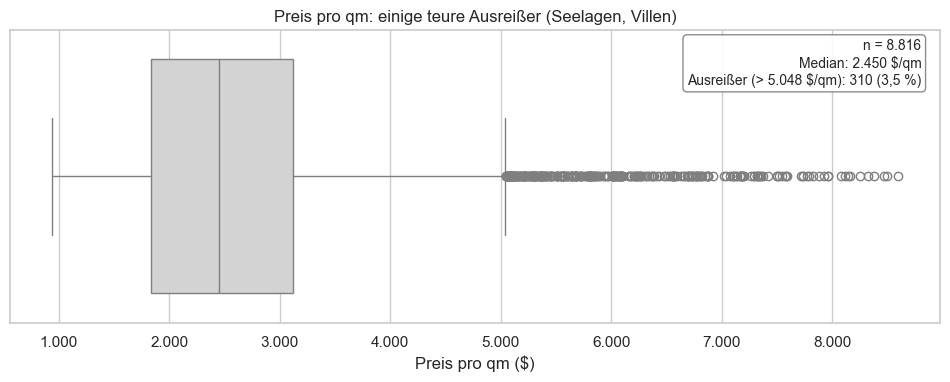

In [4]:
ZENTRUM_LAT, ZENTRUM_LON = 47.6062, -122.3321


def haversine_km(lat, lon):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat, lon, ZENTRUM_LAT, ZENTRUM_LON])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


df["km"] = haversine_km(df["lat"], df["long"])
df["qm_preis"] = df["preis_pro_qm_wohnflaeche"]
df["band"] = pd.cut(df["km"], [0, 5, 10, 15, 20, 25, 30, 80],
                    labels=["0–5", "5–10", "10–15", "15–20", "20–25", "25–30", "> 30"])

# Kontrolle: Bellevue Downtown liegt ca. 10 km vom Zentrum entfernt
print(f"Test Bellevue: {de(haversine_km(47.6101, -122.2015), 1)} km")

gross = df[df["bedrooms"] >= 4].copy()
print(f"Häuser mit mind. 4 Schlafzimmern: {de(len(gross))} von {de(len(df))}")

# Ausreißer nach der 1,5-IQR-Regel zählen
q1, q3 = gross["qm_preis"].quantile([0.25, 0.75])
grenze = q3 + 1.5 * (q3 - q1)
n_ausreisser = (gross["qm_preis"] > grenze).sum()

fig, ax = plt.subplots(figsize=(12, 3.8))
sns.boxplot(x=gross["qm_preis"], color="lightgray", ax=ax)
ax.set_title("Preis pro qm: einige teure Ausreißer (Seelagen, Villen)")
ax.set_xlabel("Preis pro qm ($)")
ax.xaxis.set_major_formatter(lambda x, _: de(x))
kennzahlen(ax, f"n = {de(len(gross))}\nMedian: {de(gross['qm_preis'].median())} $/qm\n"
               f"Ausreißer (> {de(grenze)} $/qm): {de(n_ausreisser)} ({de(100 * n_ausreisser / len(gross), 1)} %)")
plt.show()

**Kennzahlen:** n = 8.816 große Häuser · Median 2.450 $/qm · 310 Ausreißer über 5.048 $/qm (3,5 %, 1,5-IQR-Regel)

**Entscheidung:** Die Ausreißer beim qm-Preis sind echte Verkäufe (z. B. Häuser direkt am Wasser), keine Fehler. Wir arbeiten mit **Medianen** und der **Spearman-Rangkorrelation**, die beide kaum auf Ausreißer reagieren. Deshalb **löschen wir nichts**.

---
## 3. Daten erkunden
Wir schauen uns die beiden Merkmale für die Hypothese einzeln an: Wie weit liegen die großen Häuser vom Zentrum entfernt, und wie ist der qm-Preis verteilt?

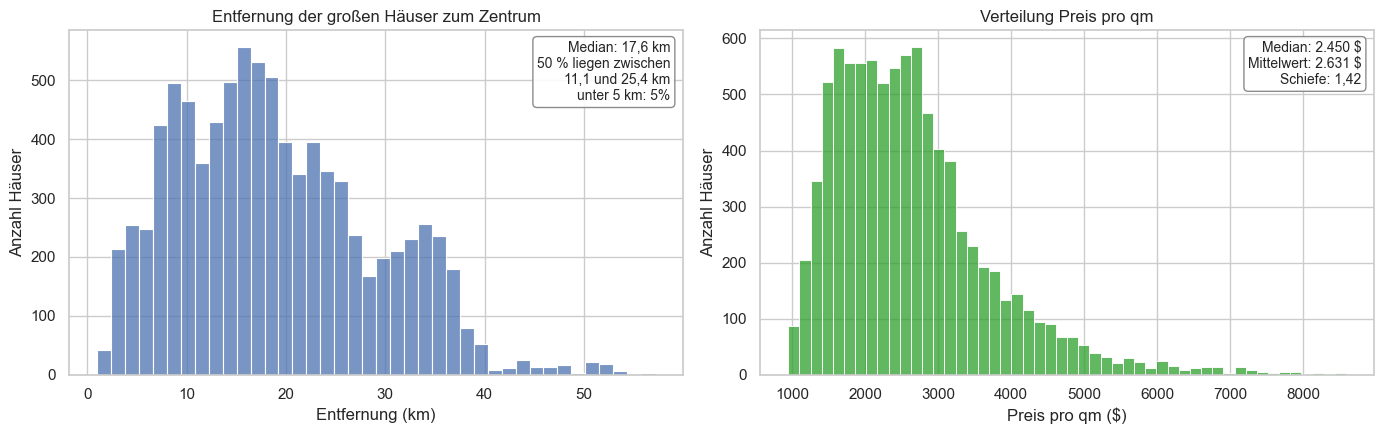

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(gross["km"], bins=40, ax=axes[0])
axes[0].set_title("Entfernung der großen Häuser zum Zentrum")
axes[0].set_xlabel("Entfernung (km)")
axes[0].set_ylabel("Anzahl Häuser")
kennzahlen(axes[0], f"Median: {de(gross['km'].median(), 1)} km\n"
                    f"50 % liegen zwischen\n{de(gross['km'].quantile(0.25), 1)} und {de(gross['km'].quantile(0.75), 1)} km\n"
                    f"unter 5 km: {(gross['km'] < 5).mean():.0%}")

sns.histplot(gross["qm_preis"], bins=50, ax=axes[1], color="tab:green")
axes[1].set_title("Verteilung Preis pro qm")
axes[1].set_xlabel("Preis pro qm ($)")
axes[1].set_ylabel("Anzahl Häuser")
kennzahlen(axes[1], f"Median: {de(gross['qm_preis'].median())} $\nMittelwert: {de(gross['qm_preis'].mean())} $\n"
                    f"Schiefe: {de(gross['qm_preis'].skew(), 2)}")
plt.tight_layout()
plt.show()

**Kennzahlen:** Median-Entfernung 17,6 km · die mittleren 50 % liegen zwischen 11,1 und 25,4 km · nur 5 % unter 5 km · qm-Preis: Median 2.450 $, Mittelwert 2.631 $, Schiefe 1,42

**Was bedeutet das?** Die meisten großen Häuser liegen **10 bis 30 km** vom Zentrum entfernt, direkt in der Innenstadt gibt es nur wenige. Der qm-Preis ist rechtsschief (Mittelwert > Median). Das ist ein weiterer Grund, mit Medianen und Rängen zu arbeiten.

---
## 4. Zusammenhänge
**Methode:** Wir nutzen eine **Spearman-Korrelationsmatrix**. Spearman vergleicht Rangfolgen statt Rohwerten. Das passt hier gut, weil der qm-Preis schief verteilt ist und wir nicht unbedingt einen geraden (linearen) Zusammenhang erwarten.

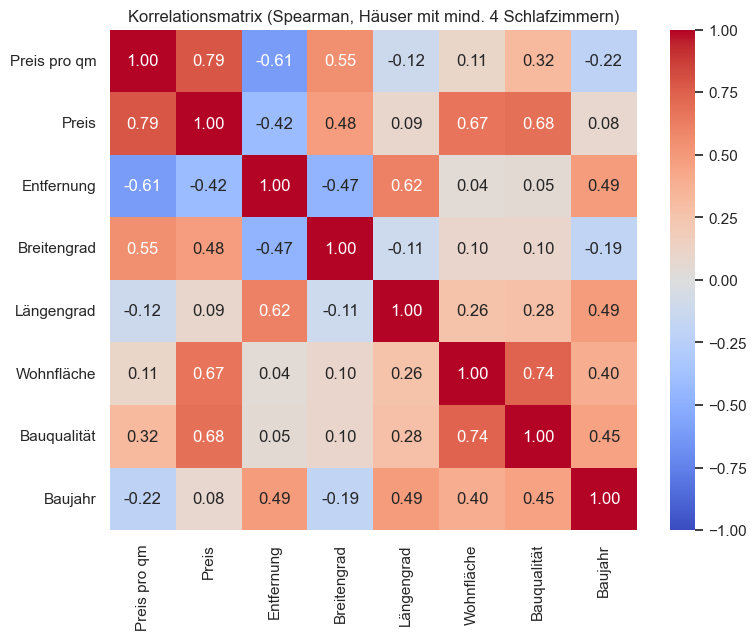

Korrelation mit dem Preis pro qm:
Entfernung    -0.61
Baujahr       -0.22
Längengrad    -0.12
Wohnfläche     0.11
Bauqualität    0.32
Breitengrad    0.55
Preis          0.79
Name: Preis pro qm, dtype: float64


In [6]:
namen = {"qm_preis": "Preis pro qm", "price": "Preis", "km": "Entfernung", "lat": "Breitengrad",
         "long": "Längengrad", "qm_living": "Wohnfläche", "grade": "Bauqualität", "yr_built": "Baujahr"}
korr = gross[list(namen)].corr(method="spearman").rename(index=namen, columns=namen)

plt.figure(figsize=(8.5, 6.5))
sns.heatmap(korr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Korrelationsmatrix (Spearman, Häuser mit mind. 4 Schlafzimmern)")
plt.show()

print("Korrelation mit dem Preis pro qm:")
print(korr["Preis pro qm"].drop("Preis pro qm").sort_values().round(2))

**Kennzahlen (Korrelation mit dem Preis pro qm):** Entfernung −0,61 · Breitengrad +0,55 · Bauqualität +0,32 · Baujahr −0,22 · Längengrad −0,12 · Wohnfläche +0,11

**Was bedeutet das?** Die **Entfernung** hängt von allen Merkmalen am stärksten mit dem qm-Preis zusammen (abgesehen vom Preis selbst), stärker als Bauqualität oder Größe. Auch der **Breitengrad** ist deutlich positiv: Im Norden ist es teurer als im Süden. Das merken wir uns für die Folgefrage.

Als Nächstes schauen wir, wie sich der Median-qm-Preis von Band zu Band verändert.

       Anzahl  Median $/qm  vs. Zentrum (%)
band                                       
0–5       480     3,786.00             0.00
5–10     1423     3,423.00           -10.00
10–15    1509     2,823.00           -25.00
15–20    1820     2,422.00           -36.00
20–25    1291     2,383.00           -37.00
25–30     836     2,022.00           -47.00
> 30     1457     1,652.00           -56.00


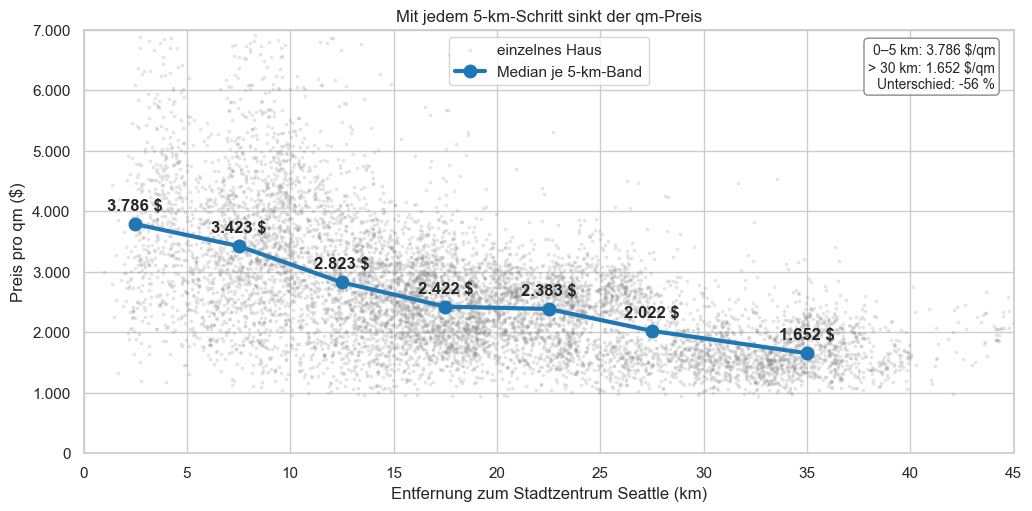

In [7]:
baender = gross.groupby("band", observed=True)["qm_preis"].agg(["size", "median"])
baender["vs. Zentrum (%)"] = 100 * (baender["median"] / baender["median"].iloc[0] - 1)
print(baender.rename(columns={"size": "Anzahl", "median": "Median $/qm"}).round(0))

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.scatter(gross["km"], gross["qm_preis"], s=3, alpha=0.15, color="gray", label="einzelnes Haus")
mitte = [2.5, 7.5, 12.5, 17.5, 22.5, 27.5, 35]
ax.plot(mitte, baender["median"], marker="o", lw=3, ms=9, color="tab:blue", label="Median je 5-km-Band")
for x, y in zip(mitte, baender["median"]):
    ax.annotate(f"{de(y)} $", (x, y), xytext=(0, 10), textcoords="offset points", ha="center", weight="bold")
ax.set_xlim(0, 45)
ax.set_ylim(0, 7000)
ax.set_xlabel("Entfernung zum Stadtzentrum Seattle (km)")
ax.set_ylabel("Preis pro qm ($)")
ax.yaxis.set_major_formatter(lambda y, _: de(y))
ax.set_title("Mit jedem 5-km-Schritt sinkt der qm-Preis")
ax.legend(loc="upper center")
kennzahlen(ax, f"0–5 km: {de(baender['median'].iloc[0])} $/qm\n> 30 km: {de(baender['median'].iloc[-1])} $/qm\n"
               f"Unterschied: {de(baender['vs. Zentrum (%)'].iloc[-1])} %")
plt.show()

**Kennzahlen:** 0–5 km: 3.786 $/qm (n = 480) · 15–20 km: 2.422 $/qm (−36 %) · über 30 km: 1.652 $/qm (−56 %, n = 1.457)

**Was bedeutet das?** Vom Zentrum bis über 30 km hinaus fällt der Median-qm-Preis Schritt für Schritt um **mehr als die Hälfte**. Nur zwischen 15–20 und 20–25 km bleibt er fast gleich. Die grauen Punkte streuen aber stark: Die Entfernung erklärt viel, aber nicht alles.

---
## 5. Hypothese prüfen
- **Spearman-Rangkorrelation (einseitig):** Wir prüfen, ob die Rangfolge „weiter weg“ zur Rangfolge „günstiger pro qm“ passt. ρ = −1 heißt perfekt gegenläufig, 0 heißt kein Zusammenhang. Wir nehmen Spearman statt Pearson, weil der qm-Preis schief ist und Ausreißer hat.
- **Faustregel pro km:** Damit Thomas etwas mit dem Ergebnis anfangen kann, legen wir eine Gerade durch den logarithmierten qm-Preis. Die Steigung können wir dann als „x % günstiger pro km“ lesen.
- **Vergleich mit kleinen Häusern:** Gilt der Effekt nur für große Häuser oder allgemein?

In [8]:
rho, p_wert = stats.spearmanr(gross["km"], gross["qm_preis"], alternative="less")
steigung = np.polyfit(gross["km"], np.log(gross["qm_preis"]), 1)[0]
pro_km = 100 * (np.exp(steigung) - 1)
pro_10km = 100 * (np.exp(steigung * 10) - 1)

klein = df[df["bedrooms"] <= 3]
rho_klein, _ = stats.spearmanr(klein["km"], klein["qm_preis"])

print(f"Spearman ρ = {de(rho, 2)}  (p {'< 0,001' if p_wert < 0.001 else '= ' + de(p_wert, 3)}, n = {de(len(gross))})")
print(f"→ {'mindestens mittelstarker' if rho <= -0.3 else 'zu schwacher'} negativer Zusammenhang")
print(f"Faustregel: {de(pro_km, 1)} % pro km, also ca. {de(pro_10km)} % pro 10 km")
print(f"Vergleich kleine Häuser (max. 3 Schlafzimmer): ρ = {de(rho_klein, 2)}")

Spearman ρ = -0,61  (p < 0,001, n = 8.816)
→ mindestens mittelstarker negativer Zusammenhang
Faustregel: -2,3 % pro km, also ca. -21 % pro 10 km
Vergleich kleine Häuser (max. 3 Schlafzimmer): ρ = -0,63


**Kennzahlen**

| Kennzahl | Wert |
|---|---|
| Spearman ρ (große Häuser, n = 8.816) | −0,61 |
| p-Wert | < 0,001 |
| Faustregel | −2,3 % pro km, ca. −21 % pro 10 km |
| Spearman ρ kleine Häuser | −0,63 |

**Was bedeutet das?**
- ρ = −0,61 ist ein **starker** negativer Zusammenhang und deutlich unter unserer Grenze von −0,3. Der p-Wert zeigt, dass das kein Zufall ist.
- Faustregel: Mit jedem km weiter weg wird der qm **gut 2 % günstiger**, also rund ein Fünftel pro 10 km.
- Kleine Häuser zeigen fast genau das gleiche Muster. Es ist also ein allgemeiner Lageeffekt und nichts Besonderes bei großen Häusern.
- **Ergebnis: H2 ist bestätigt.**

---
## 6. Folgefragen
### 6.1 Spielt die Himmelsrichtung eine Rolle?
Die Korrelationsmatrix hat gezeigt, dass es im Süden günstiger ist. Deshalb teilen wir King County grob in drei Regionen ein und schauen uns die Entfernung **pro Region** an:
- **Seattle & Norden:** westlich des Lake Washington, nördlich von 47,52°
- **Osten:** östlich von 122,24° W und nördlich von 47,52° (Bellevue, Kirkland, Redmond, „Eastside“)
- **Süden:** südlich von 47,52° (Renton, Kent, Federal Way, Auburn)

Wir zeigen nur Felder (Region × Band) mit mindestens 30 Häusern, damit einzelne Verkäufe den Median nicht verzerren.

region    Osten  Seattle & Norden    Süden
band                                      
0–5         NaN          3,786.00      NaN
5–10   4,700.00          3,223.00      NaN
10–15  3,243.00          2,726.00 1,820.00
15–20  2,740.00          2,253.00 1,865.00
20–25  2,632.00               NaN 1,785.00
25–30  2,621.00               NaN 1,606.00
> 30   2,131.00               NaN 1,571.00


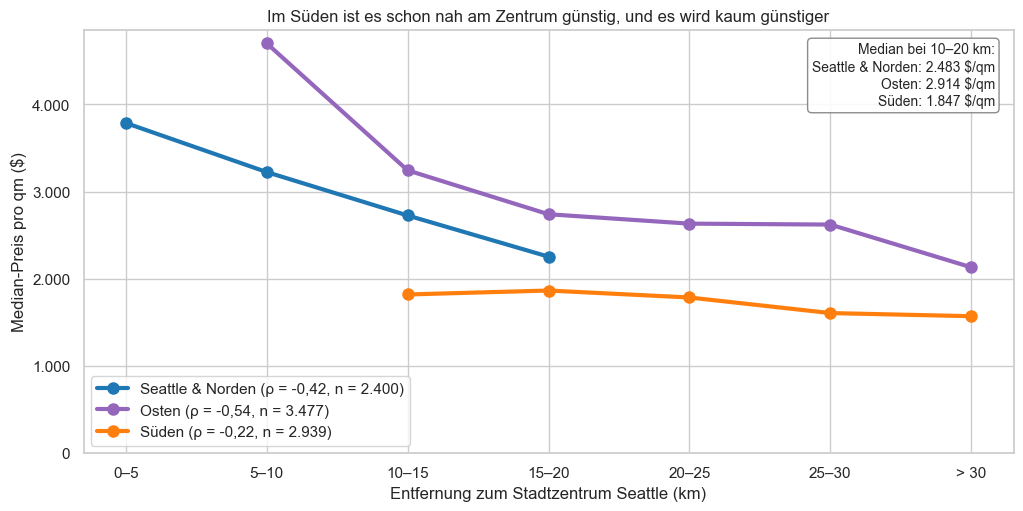

In [9]:
gross["region"] = np.select(
    [(gross["long"] >= -122.24) & (gross["lat"] >= 47.52), gross["lat"] < 47.52],
    ["Osten", "Süden"], default="Seattle & Norden")

tab = gross.pivot_table(index="band", columns="region", values="qm_preis", aggfunc="median", observed=True)
anzahl = gross.pivot_table(index="band", columns="region", values="qm_preis", aggfunc="size", observed=True)
tab = tab.where(anzahl >= 30)  # nur Felder mit genug Häusern
print(tab.round(0))

fig, ax = plt.subplots(figsize=(12, 5.5))
farben = {"Seattle & Norden": "tab:blue", "Osten": "tab:purple", "Süden": "tab:orange"}
infos = []
for region, farbe in farben.items():
    teil = gross[gross["region"] == region]
    r, _ = stats.spearmanr(teil["km"], teil["qm_preis"])
    ax.plot(tab.index.astype(str), tab[region], marker="o", lw=3, ms=8, color=farbe,
            label=f"{region} (ρ = {de(r, 2)}, n = {de(len(teil))})")
    infos.append(f"{region}: {de(teil.loc[teil['km'].between(10, 20), 'qm_preis'].median())} $/qm")
ax.set_xlabel("Entfernung zum Stadtzentrum Seattle (km)")
ax.set_ylabel("Median-Preis pro qm ($)")
ax.yaxis.set_major_formatter(lambda y, _: de(y))
ax.set_ylim(0)
ax.set_title("Im Süden ist es schon nah am Zentrum günstig, und es wird kaum günstiger")
ax.legend(loc="lower left")
kennzahlen(ax, "Median bei 10–20 km:\n" + "\n".join(infos))
plt.show()

**Kennzahlen**

| Region | Spearman ρ (Entfernung ↔ qm-Preis) | n | Median bei 10–20 km |
|---|---|---|---|
| Seattle & Norden | −0,42 | 2.400 | 2.483 $/qm |
| Osten | −0,54 | 3.477 | 2.914 $/qm |
| Süden | −0,22 | 2.939 | 1.847 $/qm |

**Was bedeutet das?** Bei **gleicher Entfernung** (10–20 km) ist der qm im Süden rund 26 % günstiger als im Norden und 37 % günstiger als im Osten als im Norden oder Osten. Im Norden und Osten wirkt die Entfernung stark, **im Süden nur schwach**: Dort ist es schon nah am Zentrum günstig. Die **Himmelsrichtung ist also fast so wichtig wie die Entfernung**.

### 6.2 Was bekommt Thomas für 600.000 $?
Damit das Ergebnis greifbar wird, rechnen wir den Median-qm-Preis pro Feld in Wohnfläche um: Budget ÷ Preis pro qm.

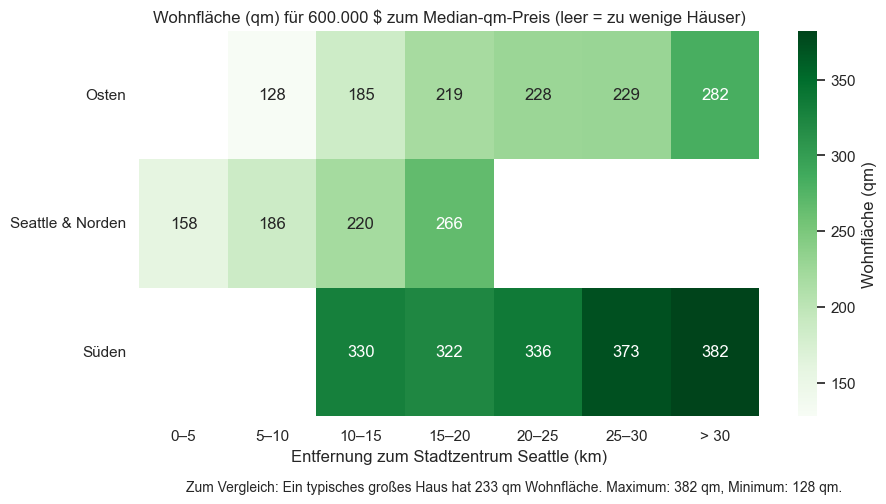

In [10]:
BUDGET = 600_000
flaeche = (BUDGET / tab).round(0)
typisch = gross["qm_living"].median()

plt.figure(figsize=(10, 5))
ax = sns.heatmap(flaeche.T, annot=True, fmt=".0f", cmap="Greens", cbar_kws={"label": "Wohnfläche (qm)"})
plt.title(f"Wohnfläche (qm) für {de(BUDGET)} $ zum Median-qm-Preis (leer = zu wenige Häuser)")
plt.grid(False)
plt.yticks(rotation=0)
plt.xlabel("Entfernung zum Stadtzentrum Seattle (km)")
plt.ylabel("")
plt.figtext(0.5, -0.04, f"Zum Vergleich: Ein typisches großes Haus hat {de(typisch)} qm Wohnfläche. "
            f"Maximum: {de(flaeche.max().max())} qm, Minimum: {de(flaeche.min().min())} qm.",
            ha="center", fontsize=10)
plt.show()

**Kennzahlen:** Zentrum (0–5 km): 158 qm · Süden 10–15 km: 330 qm · Süden über 30 km: 382 qm · Osten über 30 km: 282 qm · typisches großes Haus: 233 qm

**Was bedeutet das?** Im Zentrum reichen 600.000 $ nur für ein eher kleines Haus. Im **Süden ab 10 km** bekommt Thomas dagegen über 300 qm, also deutlich mehr als ein typisches großes Haus hat. Im Osten kommt man selbst über 30 km hinaus nur auf 282 qm.

---
## 7. Karte
Zum Schluss alles auf einer Karte für die Präsentation: Jeder Punkt ist ein großes Haus, die Farbe zeigt den Preis pro qm. Die schwarzen Ringe markieren 10, 20 und 30 km. Mit der Maus sieht man Details, mit dem Mausrad kann man zoomen. Die Karte wird auch als HTML in `output/` gespeichert.

In [11]:
karte = px.scatter_map(
    gross, lat="lat", lon="long", color="qm_preis",
    color_continuous_scale="Viridis", range_color=gross["qm_preis"].quantile([0.02, 0.98]).tolist(),
    hover_data={"price": ":,.0f", "qm_living": ":.0f", "km": ":.1f", "region": True, "lat": False, "long": False},
    labels={"qm_preis": "Preis pro qm ($)", "price": "Preis ($)", "qm_living": "Wohnfläche (qm)",
            "km": "Entfernung (km)", "region": "Region"},
    zoom=8.8, center={"lat": 47.48, "lon": -122.18}, height=720, opacity=0.7,
    title="Große Häuser in King County: gelb = teuer pro qm, lila = günstig",
)
# Entfernungsringe um das Zentrum
winkel = np.linspace(0, 2 * np.pi, 120)
for r in [10, 20, 30]:
    karte.add_trace(go.Scattermap(
        lat=ZENTRUM_LAT + r / 111.32 * np.sin(winkel),
        lon=ZENTRUM_LON + r / (111.32 * np.cos(np.radians(ZENTRUM_LAT))) * np.cos(winkel),
        mode="lines", line=dict(color="black", width=1), name=f"{r} km", hoverinfo="name", showlegend=False))
karte.add_trace(go.Scattermap(lat=[ZENTRUM_LAT], lon=[ZENTRUM_LON], mode="markers+text", text=["Zentrum"],
                              textposition="top right", marker=dict(size=14, color="red"), showlegend=False))
karte.add_annotation(
    x=0.01, y=0.02, xref="paper", yref="paper", xanchor="left", yanchor="bottom", align="left", showarrow=False,
    bgcolor="white", bordercolor="gray", borderwidth=1,
    text=(f"<b>Kennzahlen</b><br>Spearman ρ = {de(rho, 2)} (p < 0,001)<br>"
          f"Faustregel: {de(pro_km, 1)} % pro km<br>"
          f"0–5 km: {de(baender['median'].iloc[0])} $/qm<br>> 30 km: {de(baender['median'].iloc[-1])} $/qm<br>"
          f"<b>H2 bestätigt</b>"),
)
karte.update_layout(map_style="carto-positron", margin=dict(l=0, r=0, t=50, b=0), separators=",.")
karte.write_html("output/h2_karte_c.html")
karte.show()

**Was sehen wir?** Die teuren Quadratmeter (gelb) liegen rund um das Zentrum und östlich des Lake Washington. Nach außen werden die Punkte dunkler, also günstiger. Der **ganze Süden** ist schon ab dem 10-km-Ring lila.

---
## 8. Fazit

| | |
|---|---|
| Hypothese | Je weiter vom Zentrum, desto niedriger der qm-Preis (mind. 4 Schlafzimmer) |
| Spearman ρ | −0,61 (stark, p < 0,001) |
| Faustregel | ca. −2,3 % pro km |
| Zentrum vs. über 30 km | 3.786 $ → 1.652 $ pro qm (−56 %) |
| **Ergebnis** | **H2 bestätigt** |

**Erkenntnisse**
1. Weiter raus ist deutlich günstiger: pro km gut 2 % weniger pro qm, über 30 km hinaus mehr als die Hälfte.
2. Die Entfernung ist der stärkste Einzelfaktor für den qm-Preis, stärker als Bauqualität oder Hausgröße.
3. Die Himmelsrichtung zählt mit: Im Süden ist es schon nah am Zentrum günstig, im Osten bleibt es auch weit draußen teuer.

**Empfehlungen für Thomas**
1. Im Süden suchen (Renton, Kent, Federal Way, Auburn), ab ca. 10 km Entfernung: Dort bekommt er für 600.000 $ meist über 300 qm.
2. Nicht unnötig weit rausziehen: Im Süden bringt mehr Entfernung kaum noch Ersparnis, nur längere Wege für die 5 Kinder.
3. Osten und Innenstadt meiden: Dort ist der qm selbst 20–30 km draußen teurer als im Süden bei 10 km.

**Grenzen:** Luftlinie statt Fahrzeit · Regionen nur grob abgegrenzt · Schulen und Qualität der Nachbarschaft sind nicht im Datensatz · Markt von 2014/15.